# Figures for presentation

In [80]:
import numpy as np
import matplotlib.pyplot as plt
from formulas.general import L_to_tau, c, hbar
from formulas.general import s1_VdB_I1, s1_VdB_I2, s1_VdB_Ip, s1_VdB_Im

In [87]:
eta_FC1 = 0.5
eta_FC2 = 0.5

eta_PD1 = 1
eta_PD2 = 1

n = 1.5
t = 0


P_LO = 10e-3 
lam = 1550e-9 #1550 nm wavelength
omega0 = (c*2*np.pi) / lam
alpha = np.sqrt(P_LO / (hbar * omega0))

B = 1e9

print(omega0*1e-15)

1.2152590756831312


## Figure 1

In setup 1 we detect fields $\hat A_1'$ and $\hat A_2'$ in detectors 1 and 2 respectively. These can be expressed as a mean field component with a fluctuation component. The general expression for these fluctuations are

$$
\delta \hat A_1'(t) = \frac{1}{\sqrt{2\pi}} \int_0^B d\Omega \Big[  \hat a_+ f_{14}^{++} + \hat a_- f_{14}^{+-}  + \hat w_+ f_{32}^{-+} +\hat w_- f_{32}^{--} \Big] 
$$
$$
\delta\hat A_{2}'(t) = \frac{1}{\sqrt{2\pi}} \int_0^B d\Omega \Big[ \hat a_+ f_{23}^{-+} + \hat a_- f_{23}^{--} + \hat w_+ f_{41}^{++} + \hat w_- f_{41}^{+-} \Big]
$$
Where:
$$
\begin{align}
    f_{ij}^{{\pm} {\pm'}} = \left( \zeta_i {\pm} \zeta_j e^{i(\omega_0 {\pm'} \Omega)\tau} \right) e^{{\mp'}i\Omega t}
\end{align}
$$
with
$$ 
\begin{align*}
    \zeta_1 &= \sqrt{\eta_{FC_1} \eta_{FC_2}} \\
    \zeta_2 &= \sqrt{\eta_{FC_1} (1-\eta_{FC_2})} \\
    \zeta_3 &= \sqrt{(1-\eta_{FC_1}) \eta_{FC_2}} \\
    \zeta_4 &= \sqrt{(1-\eta_{FC_1}) (1-\eta_{FC_2})}
\end{align*}
$$

In [167]:
### Setup for plot 1, prefactors to modes in detected fields of setup 1

# Zeta functions
z1 = np.sqrt(eta_FC1 * eta_FC2)
z2 = np.sqrt(eta_FC1 * (1-eta_FC2))
z3 = np.sqrt((1-eta_FC1) * eta_FC2)
z4 = np.sqrt((1-eta_FC1) * (1-eta_FC2))

def f(pm, pm_, zi, zj, omega0, Omega, tau, t):
    "pm = ±, pm_ = ±'"
    exp1 = np.e**(1j*(omega0 + pm_*Omega)*tau)
    exp2 = np.e**(1j*pm_*Omega*t)
    return (zi + pm * zj*exp1)*exp2



In [ ]:
res = 500

Omega = 1e9
dLs = np.linspace(0,0.000001, res) + 20
taus = L_to_tau(n,dLs)

signal_PD1 = f(1,1,z1,z4, omega0, Omega, taus, t)
idler_PD1 = f(1,-1,z1,z4, omega0, Omega, taus, t)

signal_PD2 = f(-1,1,z2,z3, omega0, Omega, taus, t)
idler_PD2 = f(-1,-1,z2,z3, omega0, Omega, taus, t)

plt.figure()
plt.plot(dLs, signal_PD1, label="Signal PD1", c="r")
plt.plot(dLs, idler_PD1, label="Idler PD1", c="r", ls="--")
plt.plot(dLs, signal_PD2, label="Signal PD2", c="b")
plt.plot(dLs, idler_PD2, label="Idler PD2", c="b",  ls="--")

plt.xlabel(f"$\\Delta L$ $[\\mu m]$")
plt.ylabel(f"Prefactor")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.show()


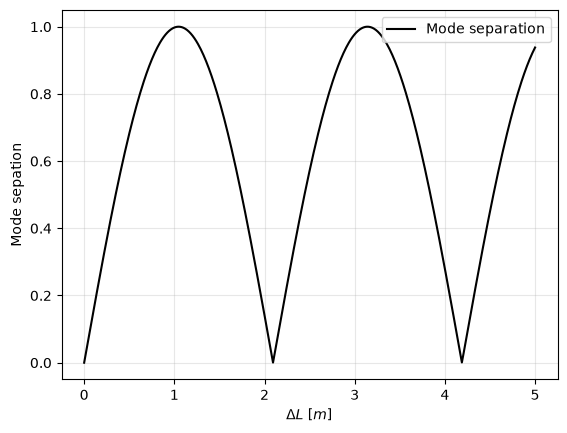

In [ ]:

res = 500

Omega = c

dLs = np.linspace(0,5, res)
taus = L_to_tau(n,dLs)

diff = np.abs(f(1,1,z1,z4,omega0, Omega, taus, t)-f(1,-1,z1,z4,omega0, Omega, taus, t))

plt.figure()
plt.plot(dLs, diff, label="Mode separation", c="k")

plt.xlabel(f"$\\Delta L$ $[ m]$")
plt.ylabel(f"Mode sepation")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.show()



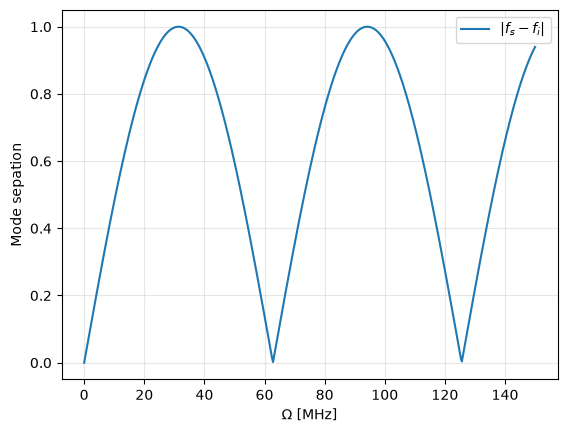

In [192]:

res = 500

Omegas = np.linspace(0,1.5e8, res)

dL = 10
tau = L_to_tau(n,dL)

diff = np.abs(f(1,1,z1,z4,omega0, Omegas, tau, t)-f(1,-1,z1,z4,omega0, Omegas, tau, t))

plt.figure()
plt.plot(Omegas*1e-6, diff, label="$|f_s - f_i|$")

plt.xlabel(f"$\\Omega $ [MHz]")
plt.ylabel(f"Mode sepation")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.show()



c:\Users\axels\Desktop\SK2004\Code\two-mode-squeezing\theory code\.venv\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\axels\Desktop\SK2004\Code\two-mode-squeezing\theory code\.venv\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


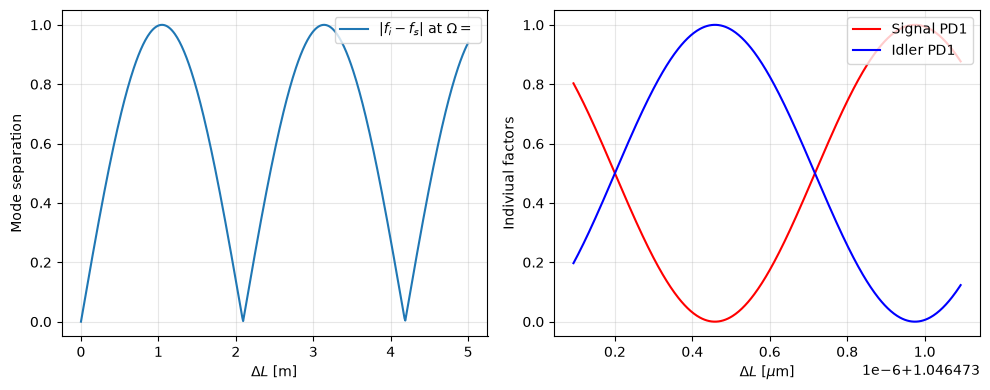

In [ ]:
# --- left: mode separation ---
res_sep = 500
Omega_sep = 3e8
dLs_sep = np.linspace(0, 5, res_sep)
taus_sep = L_to_tau(n, dLs_sep)

diff = np.abs(
    f(1, 1, z1, z4, omega0, Omega_sep, taus_sep, t)
    - f(1, -1, z1, z4, omega0, Omega_sep, taus_sep, t)
)

# --- right: signal / idler ---
res_si = 500
Omega_si = Omega_sep
dL_start = (np.pi/(2*n)) * (c/Omega_si)
dLs_si = np.linspace(0, 1e-6, res_si) + dL_start
taus_si = L_to_tau(n, dLs_si)

sig_PD1 = f(1, 1, z1, z4, omega0, Omega_si, taus_si, t)
idl_PD1 = f(1, -1, z1, z4, omega0, Omega_si, taus_si, t)
sig_PD2 = f(-1, 1, z2, z3, omega0, Omega_si, taus_si, t)
idl_PD2 = f(-1, -1, z2, z3, omega0, Omega_si, taus_si, t)

# --- plot ---
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 4))

ax0.plot(dLs_sep, diff, label="$|f_i-f_s|$ at $\\Omega=$")
ax0.set_xlabel(r"$\Delta L$ [m]")
ax0.set_ylabel("Factor difference in PD1")
ax0.legend(loc="upper right")
ax0.grid(alpha=0.3)

ax1.plot(dLs_si, sig_PD1, c="r", label="Signal PD1")
ax1.plot(dLs_si, idl_PD1, c="b", label="Idler PD1")
#ax1.plot(dLs_si, sig_PD2, c="b", label="Signal PD2")
#ax1.plot(dLs_si, idl_PD2, c="b", ls="--", label="Idler PD2")
ax1.set_xlabel(r"$\Delta L$ [$\mu$m]")
ax1.set_ylabel("Indiviual factors in PD1")
ax1.legend(loc="upper right")
ax1.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## Figure 2

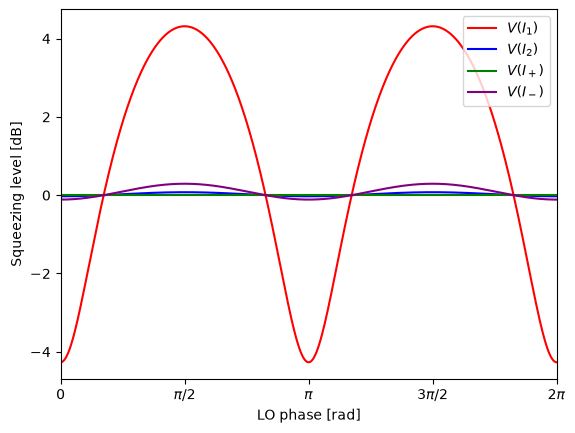

In [129]:
### 
res = 1000

Omega = 1e13

dL = 0.000001
tau = L_to_tau(n,dL)

phis = np.linspace(0,2*np.pi, res)

r = 0.5
theta = 0

VdB_I1 = s1_VdB_I1(alpha, phis, eta_FC1, eta_FC2, eta_PD1, eta_PD2, tau, r, theta, B, omega0)
VdB_I2 = s1_VdB_I2(alpha, phis, eta_FC1, eta_FC2, eta_PD1, eta_PD2, tau, r, theta, B, omega0)
VdB_Ip = s1_VdB_Ip(alpha, phis, eta_FC1, eta_FC2, eta_PD1, eta_PD2, tau, r, theta, B, omega0)
VdB_Im = s1_VdB_Im(alpha, phis, eta_FC1, eta_FC2, eta_PD1, eta_PD2, tau, r, theta, B, omega0)

plt.figure()
plt.axhline(y=0, ls="--", c="k", alpha=0.4, lw="0.7")
plt.plot(phis, VdB_I1, label="$V(I_1)$", c="r")
plt.plot(phis, VdB_I2, label="$V(I_2)$", c="b")
plt.plot(phis, VdB_Ip, label="$V(I_+)$", c="g")
plt.plot(phis, VdB_Im, label="$V(I_-)$", c="purple")

plt.xticks(
    [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi],
    [r"$0$", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)
plt.xlim(0, 2*np.pi)

plt.legend(loc="upper right")
plt.xlabel("LO phase [rad]")
plt.ylabel("Squeezing level [dB]")
plt.show()